# Phase 8B — Real RAG Context Optimization

Phase 8A measured interactions among **synthetic evidence cards**.  
Phase 8B replaces those cards with **retrieved document chunks**.

For a query \(q\) and \(n\) retrieved chunks

\[
C_q=\{c_1,\ldots,c_n\},
\]

define, for every subset \(S\subseteq C_q\),

\[
F_q(S)=Q(\text{answer}\mid q,S),
\]

where \(Q\in[0,1]\) is answer quality.

The practical objective is

\[
\boxed{
U_q(S)
=
F_q(S)
-\lambda\,\frac{Tokens_q(S)}{1000}
-\mu\,Latency_q(S)
}
\]

and the exact oracle context is

\[
S_q^\*=\arg\max_S U_q(S).
\]

Because the pilot uses only 6 candidate chunks,

\[
2^6=64
\]

subsets can still be enumerated exactly. This lets us measure the true optimum before trying approximate selectors.

## Continuity with Phase 8A

We preserve the same core tools:

- subset response surface \(F(S)\);
- Möbius decomposition;
- interaction-order spectrum;
- truncation fidelity;
- minimal sufficient context.

Phase 8B adds:

- real retrieval;
- token and latency cost;
- exact utility-optimal subset;
- prefix/reranker baseline;
- low-order interaction-aware selector;
- oracle regret;
- retrieval-support recall;
- sensitivity to \(\lambda\) and \(\mu\).

The default benchmark uses **real Wikipedia paragraphs from HotpotQA** in its distractor setting.  
A second mode accepts a custom global document corpus and query JSONL files.

## Scientific scope

The default HotpotQA mode is a **real-text RAG sandbox**:

1. each question comes with real Wikipedia paragraphs;
2. the notebook reranks those paragraphs with a retriever;
3. the top \(n\) paragraphs become candidate chunks;
4. all \(2^n\) context subsets are evaluated.

This is not yet a web-scale global retriever. For that, switch `DATA_MODE="custom"` and provide a global corpus.

The exhaustive stage is deliberately small. Do **not** increase `N_CANDIDATES` casually:

\[
n=6\Rightarrow64,\qquad
n=8\Rightarrow256,\qquad
n=10\Rightarrow1024
\]

LLM calls **per query, per repeat, per provider**.

In [1]:
# Optional one-time installation:
#
# python -m pip install -U \
#   torch transformers "huggingface-hub<1.0" accelerate safetensors \
#   datasets pandas numpy matplotlib scikit-learn
#
# For optional API providers:
# python -m pip install -U openai anthropic

import os
import re
import json
import time
import math
import hashlib
import string
import unicodedata
from pathlib import Path
from collections import Counter
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from datasets import load_dataset

BASE_SEED = 20260918
rng = np.random.default_rng(BASE_SEED)

C:\Users\Mauro\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Frozen pilot configuration

The defaults are intentionally conservative:

- 4 queries;
- 6 retrieved chunks/query;
- 64 subsets/query;
- 1 repeat;
- local deterministic generation.

That is:

\[
4\times64=256
\]

model calls for one provider.

After the pilot is clean, increase `N_QUERIES` and `N_REPEATS`.

In [2]:
DATA_MODE = "hotpot"     # "hotpot" or "custom"

N_QUERIES = 4
N_CANDIDATES = 6
N_REPEATS = 1

MAX_NEW_TOKENS = 32
EFFORT = "low"

QUALITY_METRIC = "token_f1"   # "token_f1" or "exact_match"

# Utility hyperparameters.
# These are preference weights, not monetary prices.
LAMBDA_PER_1K_TOKENS = 0.03
MU_PER_SECOND = 0.002

# Minimal sufficient context:
QUALITY_DROP_TOLERANCE = 0.05
QUALITY_FLOOR = 0.80

# Retrieval:
RETRIEVER = "tfidf"
TFIDF_NGRAM_RANGE = (1, 2)

# Local generator:
LOCAL_MODEL_ID = "Qwen/Qwen3-0.6B"
USE_LOCAL_MODEL = True

# Custom mode files:
CUSTOM_CORPUS_PATH = "phase8B_corpus.jsonl"
CUSTOM_QUESTIONS_PATH = "phase8B_questions.jsonl"

# Outputs:
MANIFEST_PATH = "phase8B_rag_manifest.jsonl"
RESULT_PATH = "phase8B_rag_raw_results.csv"
SURFACE_PATH = "phase8B_subset_surface.csv"
MOBIUS_PATH = "phase8B_mobius.csv"
SUMMARY_PATH = "phase8B_query_summary.csv"
SELECTOR_PATH = "phase8B_selector_comparison.csv"

assert 1 <= N_CANDIDATES <= 8, (
    "Keep exhaustive Phase 8B at <=8 candidates. "
    "Larger n should use approximate search."
)

N_SUBSETS = 1 << N_CANDIDATES

print("queries:", N_QUERIES)
print("candidates/query:", N_CANDIDATES)
print("subsets/query:", N_SUBSETS)
print("calls/provider:", N_QUERIES * N_SUBSETS * N_REPEATS)

queries: 4
candidates/query: 6
subsets/query: 64
calls/provider: 256


# 2. Load the local answer model

Phase 8B can be used with any caller that returns:

```python
{
    "raw_text": ...,
    "input_tokens": ...,
    "output_tokens": ...,
    "latency_sec": ...
}
```

The default is Qwen3-0.6B locally.

The fast-tokenizer failure seen in some environments is handled automatically by falling back to `use_fast=False`.

In [3]:
if USE_LOCAL_MODEL:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    try:
        local_tokenizer = AutoTokenizer.from_pretrained(
            LOCAL_MODEL_ID,
            use_fast=True,
        )
        print("fast tokenizer: OK")
    except Exception as e:
        print("fast tokenizer failed:", type(e).__name__, str(e)[:200])
        print("falling back to slow tokenizer")
        local_tokenizer = AutoTokenizer.from_pretrained(
            LOCAL_MODEL_ID,
            use_fast=False,
        )

    load_kwargs = {
        "torch_dtype": "auto",
        "low_cpu_mem_usage": True,
    }

    if DEVICE == "cuda":
        load_kwargs["device_map"] = "auto"

    local_model = AutoModelForCausalLM.from_pretrained(
        LOCAL_MODEL_ID,
        **load_kwargs,
    )
    local_model.eval()

    # Deterministic generation: sampling settings are irrelevant.
    local_model.generation_config.do_sample = False
    local_model.generation_config.temperature = None
    local_model.generation_config.top_p = None
    local_model.generation_config.top_k = None

    MODEL_DEVICE = next(local_model.parameters()).device

    print("model:", LOCAL_MODEL_ID)
    print("device:", MODEL_DEVICE)
    print("dtype:", next(local_model.parameters()).dtype)

fast tokenizer: OK
model: Qwen/Qwen3-0.6B
device: cpu
dtype: torch.bfloat16


# 3. Answer normalization and quality

Unlike Phase 8A, the answer is no longer constrained to A/B/C/D.

For real QA we use:

- normalized exact match;
- token-level F1.

The default response surface is

\[
F(S)=\text{token-F1}.
\]

This makes the Möbius transform valid for a continuous quality surface in \([0,1]\).

In [4]:
ARTICLES = {"a", "an", "the"}

def normalize_answer(s):
    s = unicodedata.normalize("NFKD", str(s))
    s = s.lower()
    s = "".join(ch for ch in s if ch not in string.punctuation)
    toks = [t for t in s.split() if t not in ARTICLES]
    return " ".join(toks)

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def token_f1(pred, gold):
    p = normalize_answer(pred).split()
    g = normalize_answer(gold).split()

    if not p and not g:
        return 1.0
    if not p or not g:
        return 0.0

    common = Counter(p) & Counter(g)
    overlap = sum(common.values())

    if overlap == 0:
        return 0.0

    precision = overlap / len(p)
    recall = overlap / len(g)

    return 2 * precision * recall / (precision + recall)

def quality_score(pred, gold):
    if QUALITY_METRIC == "exact_match":
        return exact_match(pred, gold)
    if QUALITY_METRIC == "token_f1":
        return token_f1(pred, gold)
    raise ValueError(QUALITY_METRIC)

# 4. Chunk utilities

In custom mode long documents are split into overlapping word chunks.

Schema:

### `phase8B_corpus.jsonl`

```json
{"doc_id":"d1","title":"...","text":"..."}
```

### `phase8B_questions.jsonl`

```json
{"query_id":"q1","question":"...","answer":"..."}
```

In [5]:
def chunk_words(text, chunk_words=140, overlap_words=30):
    words = str(text).split()
    if not words:
        return []

    step = max(1, chunk_words - overlap_words)
    chunks = []

    for start in range(0, len(words), step):
        part = words[start:start + chunk_words]
        if not part:
            break
        chunks.append(" ".join(part))
        if start + chunk_words >= len(words):
            break

    return chunks

def token_proxy(text):
    # Provider-independent rough token proxy.
    # Actual API/model input-token counts are also recorded later.
    return max(1, math.ceil(len(str(text)) / 4))

# 5A. HotpotQA real-text benchmark

The `distractor` split supplies a question, answer, supporting-fact titles, and a small set of real Wikipedia paragraphs.

We use TF-IDF to rank those paragraphs and take the top `N_CANDIDATES`.

This lets us measure both:

\[
\text{retrieval recall}
\]

and

\[
\text{context-subset utility}.
\]

In [6]:
def load_hotpot_validation():
    attempts = [
        ("hotpotqa/hotpot_qa", "distractor"),
        ("hotpot_qa", "distractor"),
    ]

    errors = []

    for repo, config in attempts:
        try:
            ds = load_dataset(
                repo,
                config,
                split="validation",
            )
            print("loaded:", repo, config)
            return ds
        except Exception as e:
            errors.append((repo, type(e).__name__, str(e)[:200]))

    raise RuntimeError(
        "Could not load HotpotQA. Attempts:\n" +
        "\n".join(map(str, errors))
    )

In [7]:
def hotpot_example_to_pool(ex, dataset_index):
    question = ex["question"]
    answer = ex["answer"]

    context = ex["context"]

    titles = list(context["title"])
    sentence_lists = list(context["sentences"])

    supporting_titles = set(
        ex["supporting_facts"]["title"]
    )

    pool = []

    for j, (title, sentences) in enumerate(
        zip(titles, sentence_lists)
    ):
        text = " ".join(sentences).strip()

        if not text:
            continue

        pool.append({
            "chunk_id": f"{dataset_index}:{j}",
            "doc_id": str(title),
            "title": str(title),
            "text": text,
            "is_supporting_title": bool(
                title in supporting_titles
            ),
        })

    return {
        "query_id": str(ex.get("id", dataset_index)),
        "dataset_index": int(dataset_index),
        "question": str(question),
        "answer": str(answer),
        "supporting_titles": sorted(map(str, supporting_titles)),
        "pool": pool,
    }

# 5B. Custom global RAG mode

In custom mode we create one global chunk corpus, fit a retriever once, and retrieve the top \(n\) chunks for every query.

This is the mode to use when you replace HotpotQA with your own documents.

In [8]:
def load_custom_data():
    if not os.path.exists(CUSTOM_CORPUS_PATH):
        raise FileNotFoundError(CUSTOM_CORPUS_PATH)

    if not os.path.exists(CUSTOM_QUESTIONS_PATH):
        raise FileNotFoundError(CUSTOM_QUESTIONS_PATH)

    corpus_docs = [
        json.loads(line)
        for line in open(CUSTOM_CORPUS_PATH, encoding="utf-8")
        if line.strip()
    ]

    questions = [
        json.loads(line)
        for line in open(CUSTOM_QUESTIONS_PATH, encoding="utf-8")
        if line.strip()
    ]

    chunks = []

    for doc in corpus_docs:
        for j, text in enumerate(
            chunk_words(doc["text"])
        ):
            chunks.append({
                "chunk_id": f"{doc['doc_id']}:{j}",
                "doc_id": str(doc["doc_id"]),
                "title": str(doc.get("title", doc["doc_id"])),
                "text": text,
                "is_supporting_title": None,
            })

    return chunks, questions

# 6. TF-IDF retrieval

Retrieval score is used **only to generate the candidate set**.

After that, every subset of the candidate set is evaluated independently by the answer model.

This lets us compare:

- retriever rank;
- causal/interaction structure;
- utility-optimal context.

In [9]:
def rank_pool_tfidf(question, pool, n_candidates):
    texts = [c["text"] for c in pool]

    if len(texts) < n_candidates:
        raise ValueError(
            f"Pool has only {len(texts)} chunks, "
            f"need {n_candidates}."
        )

    vect = TfidfVectorizer(
        ngram_range=TFIDF_NGRAM_RANGE,
        stop_words="english",
    )

    X = vect.fit_transform(texts + [question])
    scores = cosine_similarity(
        X[-1],
        X[:-1],
    )[0]

    order = np.argsort(-scores)[:n_candidates]

    ranked = []

    for rank, idx in enumerate(order):
        row = dict(pool[int(idx)])
        row["retrieval_rank"] = int(rank)
        row["retrieval_score"] = float(scores[int(idx)])
        row["token_proxy"] = token_proxy(row["text"])
        ranked.append(row)

    return ranked


def fit_global_tfidf(chunks):
    vect = TfidfVectorizer(
        ngram_range=TFIDF_NGRAM_RANGE,
        stop_words="english",
    )
    X = vect.fit_transform([c["text"] for c in chunks])
    return vect, X


def rank_global_tfidf(question, chunks, vect, X, n_candidates):
    q = vect.transform([question])
    scores = cosine_similarity(q, X)[0]
    order = np.argsort(-scores)[:n_candidates]

    ranked = []

    for rank, idx in enumerate(order):
        row = dict(chunks[int(idx)])
        row["retrieval_rank"] = int(rank)
        row["retrieval_score"] = float(scores[int(idx)])
        row["token_proxy"] = token_proxy(row["text"])
        ranked.append(row)

    return ranked

# 7. Build and freeze the RAG manifest

The manifest contains the exact query, answer and ranked candidate chunks.

Its SHA-256 hash becomes the run identity, preventing stale result CSVs from being silently mixed with another retrieval run.

In [10]:
rag_items = []

if DATA_MODE == "hotpot":
    hotpot = load_hotpot_validation()

    # Deterministic candidate query order.
    indices = rng.permutation(len(hotpot))

    for idx in indices:
        ex = hotpot_example_to_pool(
            hotpot[int(idx)],
            int(idx),
        )

        if len(ex["pool"]) < N_CANDIDATES:
            continue

        candidates = rank_pool_tfidf(
            ex["question"],
            ex["pool"],
            N_CANDIDATES,
        )

        rag_items.append({
            "query_id": ex["query_id"],
            "dataset_index": ex["dataset_index"],
            "question": ex["question"],
            "answer": ex["answer"],
            "supporting_titles": ex["supporting_titles"],
            "candidates": candidates,
        })

        if len(rag_items) >= N_QUERIES:
            break

elif DATA_MODE == "custom":
    chunks, questions = load_custom_data()
    vect, X = fit_global_tfidf(chunks)

    if len(questions) < N_QUERIES:
        raise RuntimeError(
            f"Only {len(questions)} custom queries available."
        )

    for q in questions[:N_QUERIES]:
        candidates = rank_global_tfidf(
            q["question"],
            chunks,
            vect,
            X,
            N_CANDIDATES,
        )

        rag_items.append({
            "query_id": str(q["query_id"]),
            "dataset_index": None,
            "question": str(q["question"]),
            "answer": str(q["answer"]),
            "supporting_titles": [],
            "candidates": candidates,
        })

else:
    raise ValueError(DATA_MODE)

assert len(rag_items) == N_QUERIES

with open(MANIFEST_PATH, "w", encoding="utf-8") as f:
    for item in rag_items:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

manifest_bytes = Path(MANIFEST_PATH).read_bytes()
MANIFEST_SHA256 = hashlib.sha256(manifest_bytes).hexdigest()

run_material = {
    "manifest_sha256": MANIFEST_SHA256,
    "data_mode": DATA_MODE,
    "n_candidates": N_CANDIDATES,
    "n_repeats": N_REPEATS,
    "quality_metric": QUALITY_METRIC,
    "local_model": LOCAL_MODEL_ID if USE_LOCAL_MODEL else None,
}

RUN_ID = hashlib.sha256(
    json.dumps(run_material, sort_keys=True).encode()
).hexdigest()[:16]

print("manifest:", MANIFEST_PATH)
print("manifest SHA256:", MANIFEST_SHA256)
print("RUN_ID:", RUN_ID)

loaded: hotpotqa/hotpot_qa distractor
manifest: phase8B_rag_manifest.jsonl
manifest SHA256: c13d90f172281ff4228ee4afa692b8e8aa6737a6906336193948c6d0f8a0be13
RUN_ID: d9b869f617fd515b


## Retrieval audit

For HotpotQA, supporting-title recall asks whether the candidate set contains the Wikipedia pages known to support the answer.

If retrieval recall is poor, context optimization cannot recover information that was never retrieved.

In [11]:
retrieval_rows = []

for item in rag_items:
    support = set(item["supporting_titles"])
    retrieved_titles = {
        c["title"] for c in item["candidates"]
    }

    if support:
        recall = len(support & retrieved_titles) / len(support)
    else:
        recall = np.nan

    retrieval_rows.append({
        "query_id": item["query_id"],
        "question": item["question"],
        "answer": item["answer"],
        "supporting_titles": sorted(support),
        "retrieved_titles": [
            c["title"] for c in item["candidates"]
        ],
        "support_recall": recall,
    })

retrieval_audit = pd.DataFrame(retrieval_rows)
display(retrieval_audit)

if DATA_MODE == "hotpot":
    print(
        "mean supporting-title recall:",
        retrieval_audit["support_recall"].mean(),
    )

,query_id,question,answer,supporting_titles,retrieved_titles,support_recall
0,5a855b5c5542997b5ce3ffeb,What is the main industry of this town with a ...,papermaking industry,"[Mexico, Maine, Mountain Valley High School]","[Mexico, Maine, Metea Valley High School, Waub...",0.5
1,5a90b1a15542990a984936ab,"Before going to the London School of Theology,...",the Netherlands,"[John Burgess (priest), Royal Dutch Shell]","[John Burgess (priest), John Burges, Graham Tw...",1.0
2,5a860aa6554299211dda2a45,"Which publication publishes more frequently, U...",The New York Enterprise Report,"[The New York Enterprise Report, Utne Reader]","[The New York Enterprise Report, Gary L. Howe,...",0.5
3,5abcd77755429965836004ce,Where did the steamship company whose former d...,Australian coast,"[Adelaide Steamship Company, Walter Leslie Dun...","[Tom Bull, Adelaide Steamship Company, Frank M...",1.0


mean supporting-title recall: 0.75


# 8. Subset representation

Candidate index \(i\) corresponds to retrieval rank \(i\).

A bitmask represents a subset:

\[
S=\{i:\; mask\;\&\;2^i\neq0\}.
\]

The full context is

\[
mask=2^n-1.
\]

In [12]:
def mask_to_indices(mask):
    return [
        i
        for i in range(N_CANDIDATES)
        if mask & (1 << i)
    ]

def mask_order(mask):
    return int(mask).bit_count()

FULL_MASK = (1 << N_CANDIDATES) - 1

def context_for_mask(item, mask):
    ids = mask_to_indices(mask)
    selected = [item["candidates"][i] for i in ids]

    if not selected:
        context = "(no retrieved context)"
    else:
        blocks = []
        for i in ids:
            c = item["candidates"][i]
            blocks.append(
                f"[C{i+1}] {c['title']}\n{c['text']}"
            )
        context = "\n\n".join(blocks)

    proxy_tokens = sum(
        item["candidates"][i]["token_proxy"]
        for i in ids
    )

    return selected, context, int(proxy_tokens)

# 9. RAG answer prompt

The generator is instructed to use only the retrieved context and to return a short answer.

This mirrors the evidence-bounded design of Phase 8A while moving from synthetic cards to real documents.

In [13]:
SYSTEM_PROMPT = (
    "Answer the question using only the retrieved context supplied by the user. "
    "If the context is insufficient, answer UNKNOWN. "
    "Return only the shortest answer span; do not explain."
)

def render_rag_prompt(item, mask):
    _, context, _ = context_for_mask(item, mask)

    return (
        f"QUESTION\n{item['question']}\n\n"
        f"RETRIEVED CONTEXT\n{context}\n\n"
        "SHORT ANSWER\n"
    )

# 10. Local deterministic caller

In [14]:
def apply_chat_template_robust(messages):
    try:
        return local_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=False,
        )
    except TypeError:
        return local_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )


def call_local_rag(user_prompt, effort=None):
    t0 = time.perf_counter()

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]

    text = apply_chat_template_robust(messages)

    inputs = local_tokenizer(
        text,
        return_tensors="pt",
    ).to(MODEL_DEVICE)

    input_len = int(inputs["input_ids"].shape[1])

    with torch.inference_mode():
        outputs = local_model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=local_tokenizer.eos_token_id,
            use_cache=True,
        )

    generated = outputs[0, input_len:]

    raw_text = local_tokenizer.decode(
        generated,
        skip_special_tokens=True,
    ).strip()

    return {
        "raw_text": raw_text,
        "returned_model": LOCAL_MODEL_ID,
        "input_tokens": input_len,
        "output_tokens": int(generated.numel()),
        "latency_sec": time.perf_counter() - t0,
        "provider_cost_usd": 0.0,
    }


CALLERS = {}
PROVIDERS = {}

if USE_LOCAL_MODEL:
    CALLERS["local"] = call_local_rag
    PROVIDERS["local"] = {
        "model": LOCAL_MODEL_ID,
        "available": True,
    }

ENABLED_PROVIDERS = list(CALLERS)
print("Enabled providers:", ENABLED_PROVIDERS)

Enabled providers: ['local']


## Optional frontier API adapters

To reuse Phase 8B with API models, add caller functions to `CALLERS` using the same return schema.

Example:

```python
CALLERS["my_provider"] = call_my_provider
PROVIDERS["my_provider"] = {"model":"...", "available":True}
ENABLED_PROVIDERS = list(CALLERS)
```

Keeping the benchmark logic provider-independent prevents model-loading problems from contaminating the experimental design.

# 11. Smoke test: empty vs full context

Before an exhaustive scan, check:

- full context answer;
- empty context answer;
- answer scores;
- latency;
- token counts.

In [15]:
smoke = rag_items[0]

for mask_name, mask in [
    ("EMPTY", 0),
    ("FULL", FULL_MASK),
]:
    prompt = render_rag_prompt(smoke, mask)
    r = CALLERS["local"](prompt)

    print("\n---", mask_name, "---")
    print("question:", smoke["question"])
    print("gold:", smoke["answer"])
    print("raw:", repr(r["raw_text"]))
    print("EM:", exact_match(r["raw_text"], smoke["answer"]))
    print("F1:", token_f1(r["raw_text"], smoke["answer"]))
    print("input tokens:", r["input_tokens"])
    print("latency:", round(r["latency_sec"], 3))


--- EMPTY ---
question: What is the main industry of this town with a population of around 2,600 as of 2010 that has Mountain Valley High School attendees as residents?
gold: papermaking industry
raw: 'UNKNOWN'
EM: 0.0
F1: 0.0
input tokens: 102
latency: 18.063

--- FULL ---
question: What is the main industry of this town with a population of around 2,600 as of 2010 that has Mountain Valley High School attendees as residents?
gold: papermaking industry
raw: 'UNKNOWN'
EM: 0.0
F1: 0.0
input tokens: 823
latency: 134.082


# 12. Resumable exhaustive subset scan

For every provider/query/subset/repeat we record:

- prediction;
- exact match;
- token F1;
- selected quality \(Q\);
- retrieval-rank mask;
- subset order;
- context-token proxy;
- actual input tokens;
- latency;
- errors.

The result file is tied to the frozen manifest hash and `RUN_ID`.

In [16]:
def call_with_retry(
    provider,
    prompt,
    max_attempts=None,
):
    # Local inference errors are not network errors:
    # retrying the same OOM/crash several times is not useful.
    if max_attempts is None:
        max_attempts = 1 if provider == "local" else 4

    err = None

    for attempt in range(max_attempts):
        try:
            return CALLERS[provider](
                prompt,
                EFFORT,
            )

        except Exception as e:
            err = e

            if provider == "local":
                raise

            wait = min(30, 2 ** attempt)

            print(
                provider,
                "failed:",
                type(e).__name__,
                str(e)[:180],
                "| wait",
                wait,
                flush=True,
            )

            time.sleep(wait)

    raise err

In [17]:
# Resume state for Phase 8B.
# IMPORTANT: Phase 8B uses query_id, not task_id.

if os.path.exists(RESULT_PATH):
    results = pd.read_csv(RESULT_PATH)

    if len(results):
        required = {
            "run_id",
            "provider",
            "query_id",
            "mask",
            "repeat",
        }

        missing = required - set(results.columns)

        if missing:
            raise RuntimeError(
                "The existing result CSV has the wrong schema. "
                f"Missing Phase-8B columns: {sorted(missing)}. "
                "It may be an old Phase-8A CSV. "
                "Rename/delete it, or point RESULT_PATH to a fresh file."
            )

        bad_runs = (
            set(results["run_id"].astype(str))
            - {str(RUN_ID)}
        )

        if bad_runs:
            raise RuntimeError(
                f"{RESULT_PATH} contains another RUN_ID: {bad_runs}. "
                "Rename/remove that CSV or use a separate output path."
            )
else:
    results = pd.DataFrame()

done = set()

if len(results):
    done = set(zip(
        results["provider"].astype(str),
        results["query_id"].astype(str),
        results["mask"].astype(int),
        results["repeat"].astype(int),
    ))

rows = (
    results.to_dict("records")
    if len(results)
    else []
)

TOTAL = (
    len(ENABLED_PROVIDERS)
    * len(rag_items)
    * N_SUBSETS
    * N_REPEATS
)

print(
    "already complete:",
    len(done),
    "/",
    TOTAL,
    flush=True, 
)

already complete: 116 / 256


In [18]:
import gc

for provider in ENABLED_PROVIDERS:

    for qi, item in enumerate(rag_items):

        for mask in range(N_SUBSETS):

            for repeat in range(N_REPEATS):

                key = (
                    str(provider),
                    str(item["query_id"]),
                    int(mask),
                    int(repeat),
                )

                if key in done:
                    continue

                print(
                    f"[{len(done)+1}/{TOTAL}] "
                    f"provider={provider} "
                    f"query={qi+1}/{len(rag_items)} "
                    f"mask={mask:02d} "
                    f"order={mask_order(mask)} "
                    f"repeat={repeat}",
                    flush=True,
                )

                prompt = render_rag_prompt(
                    item,
                    mask,
                )

                _, _, context_token_proxy = (
                    context_for_mask(
                        item,
                        mask,
                    )
                )

                t0 = time.perf_counter()

                try:
                    r = call_with_retry(
                        provider,
                        prompt,
                    )

                    em = exact_match(
                        r["raw_text"],
                        item["answer"],
                    )

                    f1 = token_f1(
                        r["raw_text"],
                        item["answer"],
                    )

                    quality = (
                        em
                        if QUALITY_METRIC == "exact_match"
                        else f1
                    )

                    row = {
                        "run_id":
                            RUN_ID,

                        "manifest_sha256":
                            MANIFEST_SHA256,

                        "provider":
                            provider,

                        "requested_model":
                            PROVIDERS[provider]["model"],

                        "returned_model":
                            r["returned_model"],

                        "query_id":
                            str(item["query_id"]),

                        "dataset_index":
                            item["dataset_index"],

                        "question":
                            item["question"],

                        "gold_answer":
                            item["answer"],

                        "mask":
                            int(mask),

                        "order":
                            mask_order(mask),

                        "repeat":
                            int(repeat),

                        "effort":
                            EFFORT,

                        "raw_text":
                            r["raw_text"],

                        "exact_match":
                            em,

                        "token_f1":
                            f1,

                        "quality":
                            quality,

                        "context_token_proxy":
                            context_token_proxy,

                        "input_tokens":
                            r["input_tokens"],

                        "output_tokens":
                            r["output_tokens"],

                        "latency_sec":
                            r["latency_sec"],

                        "provider_cost_usd":
                            r["provider_cost_usd"],

                        "error":
                            None,
                    }

                except Exception as e:

                    row = {
                        "run_id":
                            RUN_ID,

                        "manifest_sha256":
                            MANIFEST_SHA256,

                        "provider":
                            provider,

                        "requested_model":
                            PROVIDERS[provider]["model"],

                        "returned_model":
                            None,

                        "query_id":
                            str(item["query_id"]),

                        "dataset_index":
                            item["dataset_index"],

                        "question":
                            item["question"],

                        "gold_answer":
                            item["answer"],

                        "mask":
                            int(mask),

                        "order":
                            mask_order(mask),

                        "repeat":
                            int(repeat),

                        "effort":
                            EFFORT,

                        "raw_text":
                            None,

                        "exact_match":
                            np.nan,

                        "token_f1":
                            np.nan,

                        "quality":
                            np.nan,

                        "context_token_proxy":
                            context_token_proxy,

                        "input_tokens":
                            np.nan,

                        "output_tokens":
                            np.nan,

                        "latency_sec":
                            np.nan,

                        "provider_cost_usd":
                            np.nan,

                        "error":
                            f"{type(e).__name__}: {e}",
                    }

                rows.append(row)
                done.add(key)

                # Checkpoint immediately after every completed subset.
                pd.DataFrame(rows).to_csv(
                    RESULT_PATH,
                    index=False,
                )

                elapsed = (
                    time.perf_counter()
                    - t0
                )

                print(
                    f"    -> saved "
                    f"| answer={repr(row['raw_text'])} "
                    f"| quality={row['quality']} "
                    f"| elapsed={elapsed:.1f}s",
                    flush=True,
                )

                # Release Python temporaries between calls.
                gc.collect()

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

        print(
            provider,
            "query",
            qi + 1,
            "/",
            len(rag_items),
            "|",
            item["question"][:80],
            flush=True,
        )

results = pd.DataFrame(rows)

print(
    "COMPLETE:",
    len(done),
    "/",
    TOTAL,
    "| rows:",
    len(results),
    "| errors:",
    results["error"].notna().sum(),
    flush=True,
)

local query 1 / 4 | What is the main industry of this town with a population of around 2,600 as of 2
[117/256] provider=local query=2/4 mask=52 order=3 repeat=0
    -> saved | answer='UNKNOWN.' | quality=0.0 | elapsed=98.5s
[118/256] provider=local query=2/4 mask=53 order=4 repeat=0
    -> saved | answer='UNKNOWN' | quality=0.0 | elapsed=117.2s
[119/256] provider=local query=2/4 mask=54 order=4 repeat=0
    -> saved | answer='UNKNOWN' | quality=0.0 | elapsed=131.9s
[120/256] provider=local query=2/4 mask=55 order=5 repeat=0
    -> saved | answer='UNKNOWN' | quality=0.0 | elapsed=142.3s
[121/256] provider=local query=2/4 mask=56 order=3 repeat=0
    -> saved | answer='UNKNOWN' | quality=0.0 | elapsed=69.0s
[122/256] provider=local query=2/4 mask=57 order=4 repeat=0
    -> saved | answer='UNKNOWN' | quality=0.0 | elapsed=85.9s
[123/256] provider=local query=2/4 mask=58 order=4 repeat=0
    -> saved | answer='UNKNOWN' | quality=0.0 | elapsed=89.9s
[124/256] provider=local query=2/4 mask=5

### Resume note

If the kernel dies, restart it and re-run the notebook through the manifest/model setup cells, then run the Phase 8B scan again. The scan reloads `RESULT_PATH` and skips every `(provider, query_id, mask, repeat)` already checkpointed.

Do not reuse a Phase-8A result CSV here: Phase 8A uses `task_id`, while Phase 8B uses `query_id`.

# 13. Integrity and pilot audit

In [19]:
EXPECTED_ROWS = (
    len(ENABLED_PROVIDERS)
    * N_QUERIES
    * N_SUBSETS
    * N_REPEATS
)

key_cols = [
    "provider",
    "query_id",
    "mask",
    "repeat",
]

print("rows:", len(results), "/", EXPECTED_ROWS)
print("duplicate keys:", results.duplicated(key_cols).sum())
print("errors:", results["error"].notna().sum())

assert len(results) == EXPECTED_ROWS
assert not results.duplicated(key_cols).any()

audit = (
    results
    .groupby("provider")
    .agg(
        rows=("query_id", "size"),
        queries=("query_id", "nunique"),
        errors=("error", lambda x: x.notna().sum()),
        mean_quality=("quality", "mean"),
        mean_latency=("latency_sec", "mean"),
        total_input_tokens=("input_tokens", "sum"),
        total_output_tokens=("output_tokens", "sum"),
    )
)

display(audit)

rows: 256 / 256
duplicate keys: 0
errors: 0


,rows,queries,errors,mean_quality,mean_latency,total_input_tokens,total_output_tokens
provider,,,,,,,
local,256,4,0,0.186958,2007.815107,124592,1872


# 14. Estimate the real RAG response surface \(F(S)\)

For each query and subset:

\[
F(S)=\mathbb E[Q(S)]
\]

over repeats.

We also estimate:

- mean latency;
- mean input tokens;
- incremental input tokens relative to empty context.

The last quantity isolates context cost more cleanly than absolute prompt length.

In [20]:
valid = results[
    results["error"].isna()
    & results["quality"].notna()
].copy()

surface = (
    valid
    .groupby(
        ["provider", "query_id", "mask", "order"],
        as_index=False,
    )
    .agg(
        F=("quality", "mean"),
        exact_match=("exact_match", "mean"),
        token_f1=("token_f1", "mean"),
        mean_latency_sec=("latency_sec", "mean"),
        mean_input_tokens=("input_tokens", "mean"),
        context_token_proxy=("context_token_proxy", "mean"),
        n=("quality", "size"),
    )
)

# Empty-context input tokens per provider/query.
empty_tokens = (
    surface[surface["mask"] == 0]
    [["provider", "query_id", "mean_input_tokens"]]
    .rename(columns={"mean_input_tokens": "empty_input_tokens"})
)

surface = surface.merge(
    empty_tokens,
    on=["provider", "query_id"],
    how="left",
    validate="many_to_one",
)

surface["incremental_input_tokens"] = (
    surface["mean_input_tokens"]
    - surface["empty_input_tokens"]
).clip(lower=0)

surface["token_cost_basis"] = (
    surface["incremental_input_tokens"]
    .fillna(surface["context_token_proxy"])
)

surface["utility"] = (
    surface["F"]
    - LAMBDA_PER_1K_TOKENS
      * surface["token_cost_basis"] / 1000.0
    - MU_PER_SECOND
      * surface["mean_latency_sec"]
)

surface.to_csv(SURFACE_PATH, index=False)

display(surface.head())

,provider,query_id,mask,order,F,exact_match,token_f1,mean_latency_sec,mean_input_tokens,context_token_proxy,n,empty_input_tokens,incremental_input_tokens,token_cost_basis,utility
0,local,5a855b5c5542997b5ce3ffeb,0,0,0.00,0.0,0.00,75.856878,102.0,0.0,1,102.0,0.0,0.0,-0.151714
1,local,5a855b5c5542997b5ce3ffeb,1,1,0.00,0.0,0.00,113.243740,150.0,41.0,1,102.0,48.0,48.0,-0.227927
2,local,5a855b5c5542997b5ce3ffeb,2,1,0.00,0.0,0.00,134.191197,182.0,80.0,1,102.0,80.0,80.0,-0.270782
3,local,5a855b5c5542997b5ce3ffeb,3,2,0.25,0.0,0.25,187.184164,234.0,121.0,1,102.0,132.0,132.0,-0.128328
4,local,5a855b5c5542997b5ce3ffeb,4,1,0.00,0.0,0.00,144.571601,190.0,89.0,1,102.0,88.0,88.0,-0.291783


# 15. Full-context and empty-context sanity checks

Before interpreting interactions, full context should generally outperform empty context.

For HotpotQA, poor full-context performance means the answer model or prompt is too weak for the RAG optimization experiment.

In [21]:
sanity_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    empty = d[d["mask"] == 0]
    full = d[d["mask"] == FULL_MASK]

    sanity_rows.append({
        "provider": provider,
        "query_id": query_id,
        "empty_F": float(empty["F"].iloc[0]) if len(empty) else np.nan,
        "full_F": float(full["F"].iloc[0]) if len(full) else np.nan,
        "full_minus_empty": (
            float(full["F"].iloc[0] - empty["F"].iloc[0])
            if len(empty) and len(full)
            else np.nan
        ),
    })

sanity_df = pd.DataFrame(sanity_rows)
display(sanity_df)

print(
    "mean full-context F:",
    sanity_df["full_F"].mean(),
)
print(
    "mean full-empty improvement:",
    sanity_df["full_minus_empty"].mean(),
)

,provider,query_id,empty_F,full_F,full_minus_empty
0,local,5a855b5c5542997b5ce3ffeb,0.0,0.0,0.0
1,local,5a860aa6554299211dda2a45,0.0,0.0,0.0
2,local,5a90b1a15542990a984936ab,0.0,0.0,0.0
3,local,5abcd77755429965836004ce,0.0,0.0,0.0


mean full-context F: 0.0
mean full-empty improvement: 0.0


# 16. Möbius decomposition of real retrieved context

For every query:

\[
m(T)=
\sum_{U\subseteq T}
(-1)^{|T|-|U|}F(U).
\]

Interpretation:

- first order: marginal chunk contribution from the empty baseline;
- positive higher-order coefficients: complementary interaction;
- negative higher-order coefficients: redundancy/interference.

Unlike Phase 8A, there is no synthetic ground-truth interaction family. The coefficients are now empirical properties of real retrieved text.

In [22]:
def mobius_transform(f):
    m = np.asarray(f, dtype=float).copy()
    n = int(np.log2(len(m)))

    for bit in range(n):
        step = 1 << bit
        for mask in range(len(m)):
            if mask & step:
                m[mask] -= m[mask ^ step]

    return m


def inverse_mobius(m):
    f = np.asarray(m, dtype=float).copy()
    n = int(np.log2(len(f)))

    for bit in range(n):
        step = 1 << bit
        for mask in range(len(f)):
            if mask & step:
                f[mask] += f[mask ^ step]

    return f


mobius_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    d = d.sort_values("mask")

    if len(d) != N_SUBSETS:
        print("incomplete:", provider, query_id, len(d))
        continue

    f = d["F"].to_numpy()
    m = mobius_transform(f)

    recon_error = np.max(
        np.abs(f - inverse_mobius(m))
    )

    for mask, coef in enumerate(m):
        mobius_rows.append({
            "provider": provider,
            "query_id": query_id,
            "mask": mask,
            "order": mask_order(mask),
            "mobius": float(coef),
            "abs_mobius": float(abs(coef)),
            "reconstruction_error": float(recon_error),
        })

mobius_df = pd.DataFrame(mobius_rows)
mobius_df.to_csv(MOBIUS_PATH, index=False)

print(
    "max reconstruction error:",
    mobius_df["reconstruction_error"].max(),
)

max reconstruction error: 4.440892098500626e-16


# 17. Interaction-order spectrum

,provider,order,mean_signed,std_signed,mean_abs,std_abs,n_queries
0,local,0,0.000000,0.000000,0.000000,0.000000,4
1,local,1,1.602078,2.504771,1.602078,2.504771,4
2,local,2,-4.661433,7.327732,5.149748,6.915971,4
3,local,3,5.750546,9.091365,6.921753,8.292518,4
4,local,4,-2.902528,6.438105,5.419143,5.839889,4
5,local,5,0.676137,3.574878,2.577110,2.611970,4
6,local,6,-0.464799,1.346130,0.755980,1.156767,4


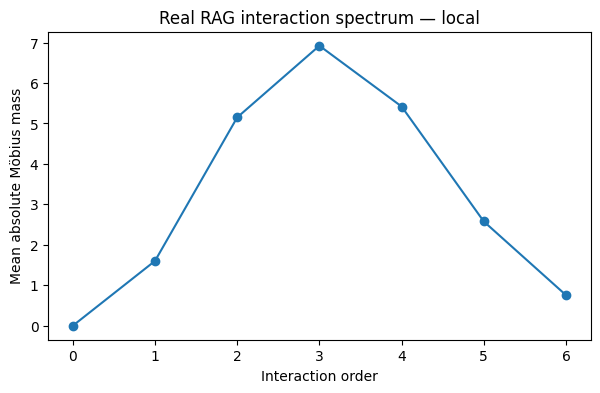

In [23]:
per_query_order = (
    mobius_df
    .groupby(
        ["provider", "query_id", "order"],
        as_index=False,
    )
    .agg(
        signed_sum=("mobius", "sum"),
        abs_sum=("mobius", "sum"),
    )
)

# Correct abs_sum explicitly:
per_query_order = (
    mobius_df
    .groupby(
        ["provider", "query_id", "order"],
        as_index=False,
    )
    .agg(
        signed_sum=("mobius", "sum"),
        abs_sum=("abs_mobius", "sum"),
    )
)

order_spectrum = (
    per_query_order
    .groupby(
        ["provider", "order"],
        as_index=False,
    )
    .agg(
        mean_signed=("signed_sum", "mean"),
        std_signed=("signed_sum", "std"),
        mean_abs=("abs_sum", "mean"),
        std_abs=("abs_sum", "std"),
        n_queries=("query_id", "nunique"),
    )
)

display(order_spectrum)

for provider in sorted(order_spectrum["provider"].unique()):
    d = order_spectrum[
        order_spectrum["provider"] == provider
    ]

    plt.figure(figsize=(7, 4))
    plt.plot(
        d["order"],
        d["mean_abs"],
        marker="o",
    )
    plt.xlabel("Interaction order")
    plt.ylabel("Mean absolute Möbius mass")
    plt.title(f"Real RAG interaction spectrum — {provider}")
    plt.show()

# 18. Strongest complementary and redundant pairs

For order-2 subsets:

\[
m(\{i,j\})>0
\]

suggests complementarity, whereas

\[
m(\{i,j\})<0
\]

suggests redundancy/interference.

The chunk titles are attached for inspection.

In [24]:
item_by_id = {
    str(item["query_id"]): item
    for item in rag_items
}

pair_rows = []

pairs = mobius_df[mobius_df["order"] == 2].copy()

for row in pairs.itertuples():
    item = item_by_id[str(row.query_id)]
    ids = mask_to_indices(int(row.mask))

    pair_rows.append({
        "provider": row.provider,
        "query_id": row.query_id,
        "mask": int(row.mask),
        "chunk_i": ids[0],
        "chunk_j": ids[1],
        "title_i": item["candidates"][ids[0]]["title"],
        "title_j": item["candidates"][ids[1]]["title"],
        "mobius_pair": float(row.mobius),
    })

pair_interactions = pd.DataFrame(pair_rows)

print("Most complementary:")
display(
    pair_interactions
    .sort_values("mobius_pair", ascending=False)
    .head(15)
)

print("Most redundant/interfering:")
display(
    pair_interactions
    .sort_values("mobius_pair", ascending=True)
    .head(15)
)

Most complementary:


,provider,query_id,mask,chunk_i,chunk_j,title_i,title_j,mobius_pair
0,local,5a855b5c5542997b5ce3ffeb,3,0,1,"Mexico, Maine",Metea Valley High School,0.250000
1,local,5a855b5c5542997b5ce3ffeb,5,0,2,"Mexico, Maine",Waubonsie Valley High School,0.210526
3,local,5a855b5c5542997b5ce3ffeb,9,0,3,"Mexico, Maine",Neuqua Valley High School,0.190476
10,local,5a855b5c5542997b5ce3ffeb,33,0,5,"Mexico, Maine",Paloma Valley High School,0.179739
4,local,5a855b5c5542997b5ce3ffeb,10,1,3,Metea Valley High School,Neuqua Valley High School,0.076923
5,local,5a855b5c5542997b5ce3ffeb,12,2,3,Waubonsie Valley High School,Neuqua Valley High School,0.068966
43,local,5a90b1a15542990a984936ab,40,3,5,Tessa Ogden,List of buildings by William Burges,0.000000
42,local,5a90b1a15542990a984936ab,36,2,5,Graham Twelftree,List of buildings by William Burges,0.000000
41,local,5a90b1a15542990a984936ab,34,1,5,John Burges,List of buildings by William Burges,0.000000
40,local,5a90b1a15542990a984936ab,33,0,5,John Burgess (priest),List of buildings by William Burges,0.000000


Most redundant/interfering:


,provider,query_id,mask,chunk_i,chunk_j,title_i,title_j,mobius_pair
24,local,5a860aa6554299211dda2a45,24,3,4,Gadfly Online,David Korten,-1.571429
20,local,5a860aa6554299211dda2a45,12,2,3,Bruce Barcott,Gadfly Online,-1.272727
19,local,5a860aa6554299211dda2a45,10,1,3,Gary L. Howe,Gadfly Online,-1.272727
26,local,5a860aa6554299211dda2a45,34,1,5,Gary L. Howe,James Nolan (author),-1.272727
15,local,5a860aa6554299211dda2a45,3,0,1,The New York Enterprise Report,Gary L. Howe,-1.000000
18,local,5a860aa6554299211dda2a45,9,0,3,The New York Enterprise Report,Gadfly Online,-1.000000
16,local,5a860aa6554299211dda2a45,5,0,2,The New York Enterprise Report,Bruce Barcott,-1.000000
25,local,5a860aa6554299211dda2a45,33,0,5,The New York Enterprise Report,James Nolan (author),-1.000000
28,local,5a860aa6554299211dda2a45,40,3,5,Gadfly Online,James Nolan (author),-1.000000
44,local,5a90b1a15542990a984936ab,48,4,5,Royal Dutch Shell,List of buildings by William Burges,-1.000000


# 19. Truncation fidelity

As in Phase 8A,

\[
\hat F_k(S)=
\sum_{T\subseteq S,\ |T|\le k}m(T).
\]

If low order reconstructs the real RAG surface well, approximate context selection may not need exhaustive search.

In [25]:
def truncated_reconstruction(m, max_order):
    z = np.asarray(m, dtype=float).copy()

    for mask in range(len(z)):
        if mask_order(mask) > max_order:
            z[mask] = 0.0

    return inverse_mobius(z)


trunc_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    d = d.sort_values("mask")

    if len(d) != N_SUBSETS:
        continue

    f = d["F"].to_numpy()
    m = mobius_transform(f)

    for k in range(1, N_CANDIDATES + 1):
        fh = truncated_reconstruction(m, k)

        trunc_rows.append({
            "provider": provider,
            "query_id": query_id,
            "max_order": k,
            "MAE": float(np.mean(np.abs(f - fh))),
            "max_error": float(np.max(np.abs(f - fh))),
        })

trunc_df = pd.DataFrame(trunc_rows)

trunc_summary = (
    trunc_df
    .groupby(
        ["provider", "max_order"],
        as_index=False,
    )
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        n_queries=("query_id", "nunique"),
    )
)

display(trunc_summary)

,provider,max_order,mean_MAE,std_MAE,n_queries
0,local,1,6.691450e-01,9.591978e-01,4
1,local,2,5.953985e-01,7.918629e-01,4
2,local,3,2.446221e-01,2.666613e-01,4
3,local,4,6.628743e-02,6.145882e-02,4
4,local,5,1.181219e-02,1.807448e-02,4
5,local,6,1.181780e-17,1.367471e-17,4


# 20. Minimal sufficient real context

For each query, the target quality is

\[
Q_{\mathrm{target}}
=
\max(
Q_{\mathrm{floor}},
F(\mathrm{full})-\epsilon
).
\]

We then find the smallest subset whose quality reaches that target.

This is the direct real-RAG analogue of Phase 8A's minimal sufficient evidence.

In [26]:
minimal_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    d = d.copy()

    full = d[d["mask"] == FULL_MASK]

    if not len(full):
        continue

    full_F = float(full["F"].iloc[0])

    target = max(
        QUALITY_FLOOR,
        full_F - QUALITY_DROP_TOLERANCE,
    )

    successful = d[d["F"] >= target].copy()

    if len(successful):
        best_size = int(successful["order"].min())

        best = successful[
            successful["order"] == best_size
        ].sort_values(
            ["utility", "F"],
            ascending=False,
        )

        best_masks = best["mask"].astype(int).tolist()
    else:
        best_size = None
        best_masks = []

    minimal_rows.append({
        "provider": provider,
        "query_id": query_id,
        "full_F": full_F,
        "target_F": target,
        "minimal_context_size": best_size,
        "minimal_masks": best_masks,
    })

minimal_df = pd.DataFrame(minimal_rows)
display(minimal_df)

,provider,query_id,full_F,target_F,minimal_context_size,minimal_masks
0,local,5a855b5c5542997b5ce3ffeb,0.0,0.8,NaN,[]
1,local,5a860aa6554299211dda2a45,0.0,0.8,1.0,"[2, 8, 4, 32]"
2,local,5a90b1a15542990a984936ab,0.0,0.8,1.0,[16]
3,local,5abcd77755429965836004ce,0.0,0.8,NaN,[]


# 21. Exact utility oracle

For every query:

\[
S^\*=
\arg\max_S U(S).
\]

This is why exhaustive Phase 8B is valuable: we know the actual optimum and can measure regret of cheaper selectors.

In [27]:
oracle_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    best = d.sort_values(
        ["utility", "F", "order"],
        ascending=[False, False, True],
    ).iloc[0]

    item = item_by_id[str(query_id)]
    ids = mask_to_indices(int(best["mask"]))

    oracle_rows.append({
        "provider": provider,
        "query_id": query_id,
        "oracle_mask": int(best["mask"]),
        "oracle_order": int(best["order"]),
        "oracle_F": float(best["F"]),
        "oracle_utility": float(best["utility"]),
        "oracle_titles": [
            item["candidates"][i]["title"]
            for i in ids
        ],
    })

oracle_df = pd.DataFrame(oracle_rows)

display(oracle_df)

,provider,query_id,oracle_mask,oracle_order,oracle_F,oracle_utility,oracle_titles
0,local,5a855b5c5542997b5ce3ffeb,3,2,0.25,-0.128328,"[Mexico, Maine, Metea Valley High School]"
1,local,5a860aa6554299211dda2a45,2,1,1.00,0.960434,[Gary L. Howe]
2,local,5a90b1a15542990a984936ab,16,1,1.00,0.649042,[Royal Dutch Shell]
3,local,5abcd77755429965836004ce,0,0,0.00,-0.023360,[]


# 22. Retrieval-prefix baseline

A standard simple RAG policy is:

> take the top \(k\) retrieved chunks.

For rank-ordered candidates this corresponds to masks

\[
0,\ 1,\ 3,\ 7,\ 15,\ldots
\]

We allow \(k\) to vary and choose the best prefix retrospectively. Even this optimistic prefix baseline can be compared with the unrestricted oracle.

In [28]:
def prefix_mask(k):
    if k <= 0:
        return 0
    return (1 << k) - 1


prefix_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    masks = [
        prefix_mask(k)
        for k in range(N_CANDIDATES + 1)
    ]

    dp = d[d["mask"].isin(masks)].copy()

    best = dp.sort_values(
        ["utility", "F"],
        ascending=False,
    ).iloc[0]

    oracle = oracle_df[
        (oracle_df["provider"] == provider)
        & (oracle_df["query_id"].astype(str) == str(query_id))
    ].iloc[0]

    prefix_rows.append({
        "provider": provider,
        "query_id": query_id,
        "prefix_mask": int(best["mask"]),
        "prefix_order": int(best["order"]),
        "prefix_F": float(best["F"]),
        "prefix_utility": float(best["utility"]),
        "oracle_utility": float(oracle["oracle_utility"]),
        "prefix_regret": float(
            oracle["oracle_utility"] - best["utility"]
        ),
    })

prefix_df = pd.DataFrame(prefix_rows)

display(prefix_df)

,provider,query_id,prefix_mask,prefix_order,prefix_F,prefix_utility,oracle_utility,prefix_regret
0,local,5a855b5c5542997b5ce3ffeb,3,2,0.250000,-0.128328,-0.128328,0.000000
1,local,5a860aa6554299211dda2a45,1,1,0.727273,0.654250,0.960434,0.306184
2,local,5a90b1a15542990a984936ab,0,0,0.000000,-0.212171,0.649042,0.861214
3,local,5abcd77755429965836004ce,0,0,0.000000,-0.023360,-0.023360,0.000000


# 23. Low-order interaction-aware selector

Now perform Möbius decomposition on **utility** itself.

For each query:

\[
U(S)=\sum_{T\subseteq S}m_U(T).
\]

Then truncate at order \(k\):

\[
\hat U_k(S)=
\sum_{\substack{T\subseteq S\\|T|\le k}}m_U(T),
\]

choose

\[
\hat S_k=\arg\max_S\hat U_k(S),
\]

and evaluate its **true** utility \(U(\hat S_k)\).

This gives a direct answer to:

> how much interaction order is required to select a near-optimal real RAG context?

In [29]:
selector_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    d = d.sort_values("mask")

    if len(d) != N_SUBSETS:
        continue

    u = d["utility"].to_numpy()
    m_u = mobius_transform(u)

    oracle_mask = int(np.argmax(u))
    oracle_utility = float(u[oracle_mask])

    for k in range(1, N_CANDIDATES + 1):
        u_hat = truncated_reconstruction(m_u, k)

        selected_mask = int(np.argmax(u_hat))
        true_selected_utility = float(u[selected_mask])

        selector_rows.append({
            "provider": provider,
            "query_id": query_id,
            "max_order": k,
            "selected_mask": selected_mask,
            "selected_order": mask_order(selected_mask),
            "predicted_utility": float(u_hat[selected_mask]),
            "true_selected_utility": true_selected_utility,
            "oracle_mask": oracle_mask,
            "oracle_utility": oracle_utility,
            "utility_regret": (
                oracle_utility - true_selected_utility
            ),
            "exact_oracle_mask": (
                selected_mask == oracle_mask
            ),
        })

selector_df = pd.DataFrame(selector_rows)
selector_df.to_csv(SELECTOR_PATH, index=False)

selector_summary = (
    selector_df
    .groupby(
        ["provider", "max_order"],
        as_index=False,
    )
    .agg(
        mean_regret=("utility_regret", "mean"),
        max_regret=("utility_regret", "max"),
        exact_oracle_rate=("exact_oracle_mask", "mean"),
        mean_selected_order=("selected_order", "mean"),
        n_queries=("query_id", "nunique"),
    )
)

display(selector_summary)

,provider,max_order,mean_regret,max_regret,exact_oracle_rate,mean_selected_order,n_queries
0,local,1,0.302110,1.185056,0.50,1.75,4
1,local,2,0.126939,0.507754,0.75,1.50,4
2,local,3,0.605185,1.185056,0.25,5.00,4
3,local,4,0.662103,1.459865,0.25,4.25,4
4,local,5,0.363660,1.185056,0.50,3.75,4
5,local,6,0.000000,0.000000,1.00,1.00,4


# 24. Compare oracle, prefix and interaction-aware order-2 selection

Order 2 is especially important because it is the first model that can represent pairwise complementarity/redundancy.

This is the practical bridge from the interaction spectrum to RAG context selection.

In [30]:
order2 = selector_df[
    selector_df["max_order"] == min(2, N_CANDIDATES)
][
    [
        "provider",
        "query_id",
        "selected_mask",
        "selected_order",
        "true_selected_utility",
        "utility_regret",
        "exact_oracle_mask",
    ]
].rename(columns={
    "selected_mask": "order2_mask",
    "selected_order": "order2_order",
    "true_selected_utility": "order2_utility",
    "utility_regret": "order2_regret",
    "exact_oracle_mask": "order2_exact_oracle",
})

comparison = (
    oracle_df
    .merge(
        prefix_df,
        on=["provider", "query_id"],
        validate="one_to_one",
    )
    .merge(
        order2,
        on=["provider", "query_id"],
        validate="one_to_one",
    )
)

display(comparison)

comparison_summary = (
    comparison
    .groupby("provider")
    .agg(
        mean_oracle_order=("oracle_order", "mean"),
        mean_prefix_regret=("prefix_regret", "mean"),
        mean_order2_regret=("order2_regret", "mean"),
        order2_exact_oracle_rate=("order2_exact_oracle", "mean"),
    )
)

display(comparison_summary)

,provider,query_id,oracle_mask,oracle_order,oracle_F,oracle_utility_x,oracle_titles,prefix_mask,prefix_order,prefix_F,prefix_utility,oracle_utility_y,prefix_regret,order2_mask,order2_order,order2_utility,order2_regret,order2_exact_oracle
0,local,5a855b5c5542997b5ce3ffeb,3,2,0.25,-0.128328,"[Mexico, Maine, Metea Valley High School]",3,2,0.250000,-0.128328,-0.128328,0.000000,15,4,-0.636082,0.507754,False
1,local,5a860aa6554299211dda2a45,2,1,1.00,0.960434,[Gary L. Howe],1,1,0.727273,0.654250,0.960434,0.306184,2,1,0.960434,0.000000,True
2,local,5a90b1a15542990a984936ab,16,1,1.00,0.649042,[Royal Dutch Shell],0,0,0.000000,-0.212171,0.649042,0.861214,16,1,0.649042,0.000000,True
3,local,5abcd77755429965836004ce,0,0,0.00,-0.023360,[],0,0,0.000000,-0.023360,-0.023360,0.000000,0,0,-0.023360,0.000000,True


,mean_oracle_order,mean_prefix_regret,mean_order2_regret,order2_exact_oracle_rate
provider,,,,
local,1.0,0.291849,0.126939,0.75


# 25. Utility sensitivity without additional LLM calls

Once \(F(S)\), token cost and latency are measured, \(\lambda\) and \(\mu\) can be swept offline.

This tests whether the selected context is robust to the engineering tradeoff.

In [31]:
LAMBDA_GRID = [0.0, 0.01, 0.03, 0.06, 0.10]
MU_GRID = [0.0, 0.001, 0.002, 0.005]

sensitivity_rows = []

for (provider, query_id), d in surface.groupby(
    ["provider", "query_id"]
):
    for lam in LAMBDA_GRID:
        for mu in MU_GRID:
            utility = (
                d["F"].to_numpy()
                - lam
                  * d["token_cost_basis"].to_numpy()
                  / 1000.0
                - mu
                  * d["mean_latency_sec"].to_numpy()
            )

            best_pos = int(np.argmax(utility))
            best = d.iloc[best_pos]

            sensitivity_rows.append({
                "provider": provider,
                "query_id": query_id,
                "lambda_per_1k_tokens": lam,
                "mu_per_second": mu,
                "selected_mask": int(best["mask"]),
                "selected_order": int(best["order"]),
                "selected_F": float(best["F"]),
                "selected_utility": float(utility[best_pos]),
            })

sensitivity_df = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_df.head(20)
)

,provider,query_id,lambda_per_1k_tokens,mu_per_second,selected_mask,selected_order,selected_F,selected_utility
0,local,5a855b5c5542997b5ce3ffeb,0.00,0.000,23,4,0.444444,0.444444
1,local,5a855b5c5542997b5ce3ffeb,0.00,0.001,43,4,0.444444,0.106559
2,local,5a855b5c5542997b5ce3ffeb,0.00,0.002,3,2,0.250000,-0.124368
3,local,5a855b5c5542997b5ce3ffeb,0.00,0.005,0,0,0.000000,-0.379284
4,local,5a855b5c5542997b5ce3ffeb,0.01,0.000,35,3,0.444444,0.441354
5,local,5a855b5c5542997b5ce3ffeb,0.01,0.001,43,4,0.444444,0.102539
6,local,5a855b5c5542997b5ce3ffeb,0.01,0.002,3,2,0.250000,-0.125688
7,local,5a855b5c5542997b5ce3ffeb,0.01,0.005,0,0,0.000000,-0.379284
8,local,5a855b5c5542997b5ce3ffeb,0.03,0.000,35,3,0.444444,0.435174
9,local,5a855b5c5542997b5ce3ffeb,0.03,0.001,43,4,0.444444,0.094499


# 26. Query-level bridge summary

The compact output records, for every query:

- retrieval support recall;
- empty/full quality;
- minimal sufficient context size;
- utility oracle;
- best retriever prefix;
- order-2 interaction-aware selection.

In [32]:
query_summary = (
    sanity_df
    .merge(
        retrieval_audit[
            ["query_id", "support_recall"]
        ],
        on="query_id",
        how="left",
    )
    .merge(
        minimal_df,
        on=["provider", "query_id"],
        how="left",
    )
    .merge(
        oracle_df,
        on=["provider", "query_id"],
        how="left",
    )
    .merge(
        prefix_df[
            [
                "provider",
                "query_id",
                "prefix_mask",
                "prefix_order",
                "prefix_utility",
                "prefix_regret",
            ]
        ],
        on=["provider", "query_id"],
        how="left",
    )
    .merge(
        order2,
        on=["provider", "query_id"],
        how="left",
    )
)

query_summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

display(query_summary)

,provider,query_id,empty_F,full_F_x,full_minus_empty,support_recall,full_F_y,target_F,minimal_context_size,minimal_masks,...,oracle_titles,prefix_mask,prefix_order,prefix_utility,prefix_regret,order2_mask,order2_order,order2_utility,order2_regret,order2_exact_oracle
0,local,5a855b5c5542997b5ce3ffeb,0.0,0.0,0.0,0.5,0.0,0.8,NaN,[],...,"[Mexico, Maine, Metea Valley High School]",3,2,-0.128328,0.000000,15,4,-0.636082,0.507754,False
1,local,5a860aa6554299211dda2a45,0.0,0.0,0.0,0.5,0.0,0.8,1.0,"[2, 8, 4, 32]",...,[Gary L. Howe],1,1,0.654250,0.306184,2,1,0.960434,0.000000,True
2,local,5a90b1a15542990a984936ab,0.0,0.0,0.0,1.0,0.0,0.8,1.0,[16],...,[Royal Dutch Shell],0,0,-0.212171,0.861214,16,1,0.649042,0.000000,True
3,local,5abcd77755429965836004ce,0.0,0.0,0.0,1.0,0.0,0.8,NaN,[],...,[],0,0,-0.023360,0.000000,0,0,-0.023360,0.000000,True


# 27. Pilot decision gate

Do not scale immediately.

Check:

1. error rate is near zero;
2. full-context quality is materially above empty-context quality;
3. retrieval support recall is acceptable;
4. real-context interaction spectra are non-degenerate;
5. order-2 or order-3 truncation has reasonable fidelity;
6. interaction-aware selection has lower regret than the retrieval-prefix baseline;
7. results persist when `N_REPEATS=3`;
8. selected contexts remain reasonably stable across \(\lambda,\mu\).

Only then increase query count or candidate count.

In [33]:
pilot_report = {
    "run_id": RUN_ID,
    "manifest_sha256": MANIFEST_SHA256,
    "data_mode": DATA_MODE,
    "n_queries": N_QUERIES,
    "n_candidates": N_CANDIDATES,
    "n_subsets": N_SUBSETS,
    "n_repeats": N_REPEATS,
    "quality_metric": QUALITY_METRIC,
    "lambda_per_1k_tokens": LAMBDA_PER_1K_TOKENS,
    "mu_per_second": MU_PER_SECOND,
    "error_rate": float(results["error"].notna().mean()),
    "mean_empty_F": float(sanity_df["empty_F"].mean()),
    "mean_full_F": float(sanity_df["full_F"].mean()),
    "mean_full_minus_empty": float(
        sanity_df["full_minus_empty"].mean()
    ),
    "mean_support_recall": (
        None
        if retrieval_audit["support_recall"].isna().all()
        else float(retrieval_audit["support_recall"].mean())
    ),
    "mean_prefix_regret": float(
        comparison["prefix_regret"].mean()
    ),
    "mean_order2_regret": float(
        comparison["order2_regret"].mean()
    ),
    "order2_exact_oracle_rate": float(
        comparison["order2_exact_oracle"].mean()
    ),
}

print(json.dumps(pilot_report, indent=2))

with open(
    "phase8B_pilot_report.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        pilot_report,
        f,
        indent=2,
    )

{
  "run_id": "d9b869f617fd515b",
  "manifest_sha256": "c13d90f172281ff4228ee4afa692b8e8aa6737a6906336193948c6d0f8a0be13",
  "data_mode": "hotpot",
  "n_queries": 4,
  "n_candidates": 6,
  "n_subsets": 64,
  "n_repeats": 1,
  "quality_metric": "token_f1",
  "lambda_per_1k_tokens": 0.03,
  "mu_per_second": 0.002,
  "error_rate": 0.0,
  "mean_empty_F": 0.0,
  "mean_full_F": 0.0,
  "mean_full_minus_empty": 0.0,
  "mean_support_recall": 0.75,
  "mean_prefix_regret": 0.29184936033181696,
  "mean_order2_regret": 0.1269385406499991,
  "order2_exact_oracle_rate": 0.75
}


# Interpretation

Phase 8B is successful if it establishes a reproducible distinction between:

\[
\boxed{\text{retrieval relevance}}
\]

and

\[
\boxed{\text{context utility after interaction}}
\]

A high-ranked chunk need not belong to the utility-optimal context if it is redundant, distracting, or expensive.

Likewise, two individually weak chunks can become useful together if they carry complementary evidence.

The key experimental quantities are therefore:

\[
F(S)
\]

for answer quality,

\[
m(T)
\]

for interaction structure,

and

\[
U(S)
=
F(S)
-\lambda Tokens(S)
-\mu Latency(S)
\]

for deployment-oriented context selection.

The next scaling step should **not** enumerate \(2^n\) subsets.  
Instead, use the exhaustive pilot as ground truth to test approximate search:

- greedy marginal utility;
- pair-aware greedy;
- beam search;
- low-order Möbius surrogate;
- learned subset selector.

That becomes the natural bridge from Phase 8B toward an adaptive RAG controller.